## Imports y configuración

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold #funciones para busqueda de hiperparametros y K-fold estratificado
#modelos
from sklearn.linear_model import LogisticRegression 
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
#metricas
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report
)
from sklearn.utils.class_weight import compute_class_weight

import xgboost as xgb #XGBoost

#MLP
from tensorflow import keras
from scikeras.wrappers import KerasClassifier

sns.set_theme(style="whitegrid")
PALETTE = "Set2"
SET2 = sns.color_palette(PALETTE)

FIG_DIR = "../figuras/modelado"
MODEL_DIR = "../modelos"
RESULTS_DIR = "../resultados"
DATA_DIR = "../data"

for carpeta in [FIG_DIR, MODEL_DIR, RESULTS_DIR]:
    os.makedirs(carpeta, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

I0000 00:00:1790453912.580229    3628 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1790453913.831322    3628 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Carga de los datos

In [2]:
#cargamos X_train y X_test
X_train = pd.read_csv(DATA_DIR + "/X_train_proc.csv")
X_test = pd.read_csv(DATA_DIR + "/X_test_proc.csv")
#cargamos unica columna del csv de y_train e y_test
y_train = pd.read_csv(DATA_DIR + "/y_train.csv").iloc[:, 0] 
y_test = pd.read_csv(DATA_DIR + "/y_test.csv").iloc[:, 0]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nDistribución de y_train:")
print(y_train.value_counts(normalize=True).round(4))

print("\nDistribución de y_test:")
print(y_test.value_counts(normalize=True).round(4))

feature_names = X_train.columns #vector con nombre de las columnas (variables caracteristicas)

X_train: (27600, 25)
X_test: (6900, 25)

Distribución de y_train:
returned
0    0.9449
1    0.0551
Name: proportion, dtype: float64

Distribución de y_test:
returned
0    0.9448
1    0.0552
Name: proportion, dtype: float64


In [3]:
#Calculo de pesos para tener en cuenta en los modelos la clase minoritaria

pesos = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
) #pesos para tener en cuenta que una equivocacion en la clase minoritaria debe influir mas en el aprendizaje de los modelos

class_weight_dict = {0: pesos[0], 1: pesos[1]}
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print("Pesos:", class_weight_dict)
print("scale_pos_weight:", round(scale_pos_weight, 3))

Pesos: {0: np.float64(0.5291816857120945), 1: np.float64(9.067017082785808)}
scale_pos_weight: 17.134


In [4]:
#diccionarios para guardar los resultados de los modelos y su tiempo de entrenamiento
resultados_modelos = {}
tiempos_entrenamiento = {}

#FUNCION PARA EVALUAR MODELOS UNA VEZ YA ENTRENADOS
def evaluar_modelo(y_real, probabilidades, nombre, etiqueta):
    predicciones = (probabilidades >= 0.5).astype(int) #probabilidad >= 0.5 ---> devuelto | probabilidad < 0.5 ---> No devuelto

    #sacamos metricas del modelo guardandolas en un diccionario todas
    resultados = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, predicciones),
        "Precision": precision_score(y_real, predicciones, zero_division=0),
        "Recall": recall_score(y_real, predicciones, zero_division=0),
        "F1": f1_score(y_real, predicciones, zero_division=0),
        "F2": fbeta_score(y_real, predicciones, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_real, probabilidades),
        "PR-AUC": average_precision_score(y_real, probabilidades)
    }

    print("\n", nombre)
    #Imprimimos metricas por clase (classification report), para mas informacion
    print(classification_report(
        y_real,
        predicciones,
        target_names=["No devuelto", "Devuelto"],
        zero_division=0
    ))

    #Imprimimos metricas de evaluacion redondeadas a 4 decimales
    print("Accuracy:", round(resultados["Accuracy"], 4))
    print("Precision:", round(resultados["Precision"], 4))
    print("Recall:", round(resultados["Recall"], 4))
    print("F1:", round(resultados["F1"], 4))
    print("F2:", round(resultados["F2"], 4))
    print("ROC-AUC:", round(resultados["ROC-AUC"], 4))
    print("PR-AUC:", round(resultados["PR-AUC"], 4))

    # Matriz de confusión con su mapa de colores
    cm = confusion_matrix(y_real, predicciones)
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["No devuelto", "Devuelto"],
        yticklabels=["No devuelto", "Devuelto"]
    )
    plt.xlabel("Predicción")
    plt.ylabel("Valor real")
    plt.title("Matriz de confusión — " + nombre)
    plt.tight_layout()
    plt.savefig(FIG_DIR + "/modelado_confusion_" + etiqueta + ".png", dpi=150)
    plt.show()

    # Curva ROC
    fpr, tpr, _ = roc_curve(y_real, probabilidades)
    plt.figure(figsize=(5, 4.5))
    plt.plot(fpr, tpr, color=SET2[0], label=nombre + " (AUC = " + str(round(resultados["ROC-AUC"], 3)) + ")")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="Clasificador aleatorio") #discriminador aleatorio
    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")
    plt.title("Curva ROC — " + nombre)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR + "/modelado_roc_" + etiqueta + ".png", dpi=150)
    plt.show()

    # Curva Precision-Recall
    precision, recall, _ = precision_recall_curve(y_real, probabilidades)
    plt.figure(figsize=(5, 4.5))
    plt.plot(recall, precision, color=SET2[1], label=nombre + " (PR-AUC = " + str(round(resultados["PR-AUC"], 3)) + ")")
    plt.axhline(y_real.mean(), linestyle="--", color="gray",
                label="Clasificador aleatorio (PR-AUC = " + str(round(y_real.mean(), 3)) + ")") #Clasificador aleatorio
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Curva Precision-Recall — " + nombre)
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIG_DIR + "/modelado_pr_" + etiqueta + ".png", dpi=150)
    plt.show()

    #guardamos resultados de metricas en el diccionario resultados_modelos, que actua como variable global y como diccionario de diccionarios
    resultados_modelos[nombre] = resultados
    return resultados

## Regresión Logística

In [5]:
#BUSQUEDA DE HIPERPARAMETROS Y ENTRENAMIENTO DE LA REGRESION LOGISTICA

param_grid = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100],        #Diccionario con los hiperparametros C y penalty que vamos a explorar (6 x 2 = 12 combinaciones)
    "penalty": ["l1", "l2"]                      
}                                             

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  #K-fold estratificado con 5 bolsas, semilla fija (para reproducibilidad de resultados) y shuffle inicial. Se usara a partir de aqui

#modelo de regresion logistica con class_weight balanced para dar mas importancia a la variable minoritaria, maximo de iteraciones de entrenamiento que usa el algoritmo de busqueda de los coeficientes sera de 2000 
lr = LogisticRegression(
    solver="liblinear",
    class_weight="balanced",
    max_iter=2000,
    random_state=RANDOM_STATE
)                               

#Busqueda del modelo con los mejores hiperparametros, escogiendo el modelo con los hiperparametros que den mejor PR-AUC
grid_lr = GridSearchCV(
    lr,
    param_grid,
    scoring="average_precision",
    cv=cv
) 

#Entrenamiento del modelo
inicio = time.time()
grid_lr.fit(X_train, y_train)
tiempos_entrenamiento["Regresión Logística"] = time.time() - inicio

modelo_lr = grid_lr.best_estimator_

print("Mejores parámetros:", grid_lr.best_params_)
print("PR-AUC CV:", round(grid_lr.best_score_, 4))
print("Tiempo:", round(tiempos_entrenamiento["Regresión Logística"], 1), "s")

Mejores parámetros: {'C': 0.01, 'penalty': 'l1'}
PR-AUC CV: 0.075
Tiempo: 5.3 s



 Regresión Logística
              precision    recall  f1-score   support

 No devuelto       0.96      0.50      0.66      6519
    Devuelto       0.07      0.68      0.13       381

    accuracy                           0.51      6900
   macro avg       0.52      0.59      0.40      6900
weighted avg       0.91      0.51      0.63      6900

Accuracy: 0.5103
Precision: 0.0737
Recall: 0.6798
F1: 0.1329
F2: 0.2569
ROC-AUC: 0.6179
PR-AUC: 0.0783


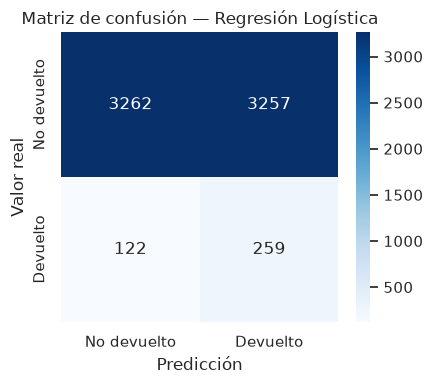

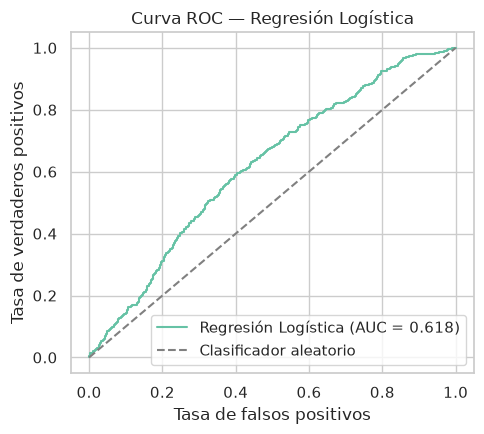

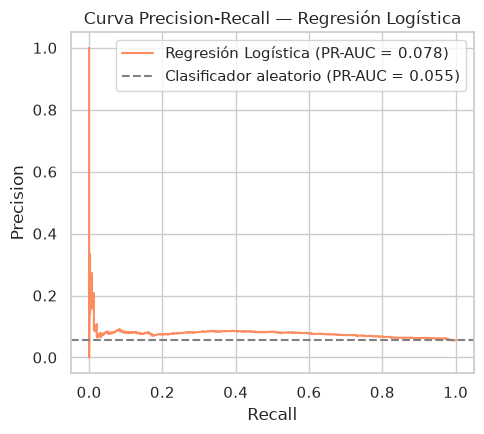

Modelo guardado.


In [6]:
#PREDICCIONES Y EVALUACION DE LA REGRESION LOGISTICA
#Sacamos probabilidades de que el pedido sea devuelto y evaluamos los resultados
proba_lr = modelo_lr.predict_proba(X_test)[:, 1]
evaluar_modelo(y_test, proba_lr, "Regresión Logística", "lr")

joblib.dump(modelo_lr, MODEL_DIR + "/logistic_regression.joblib")
print("Modelo guardado.")

category_Grocery       -1.003349
category_Fashion        0.429256
shipping_cost           0.163396
category_Electronics    0.084913
profit_margin          -0.047643
quantity               -0.020747
price                   0.015894
total_amount            0.000000
delivery_time_days      0.000000
customer_age            0.000000
discount                0.000000
category_Home           0.000000
dtype: float64


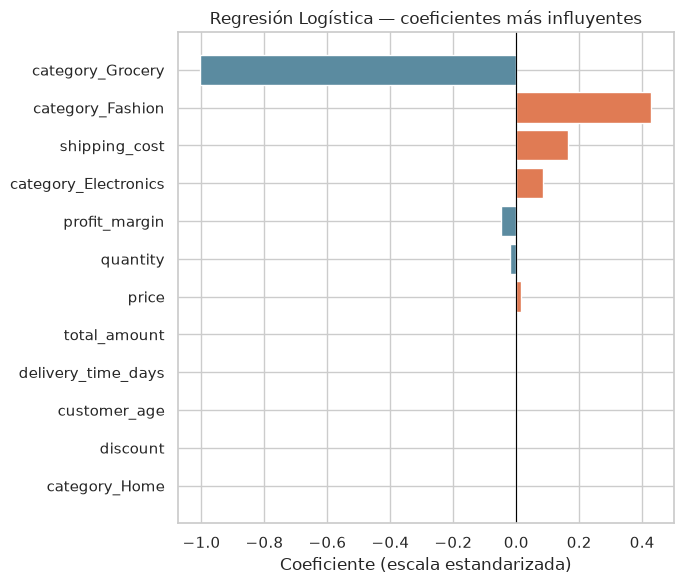

In [7]:
coeficientes = pd.Series(
    modelo_lr.coef_[0], #valores de los coeficientes
    index=feature_names
).sort_values(key=abs, ascending=False) #ordenamos en valor absoluto y en orden decreciente los valores de los coeficientes que acompañan a cada variable

print(coeficientes.head(12))

#dibujamos los 12 coeficientes mas influyentes del modelo de regresion logistica
top_coef = coeficientes.head(12)[::-1]
colores = ["#e07b54" if v > 0 else "#5b8ba0" for v in top_coef.values] #naranja si aumenta la probabilidad de devolucion, azul si la reduce
plt.figure(figsize=(7, 6))
plt.barh(top_coef.index, top_coef.values, color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente (escala estandarizada)")
plt.title("Regresión Logística — coeficientes más influyentes")
plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_coeficientes_lr.png", dpi=150)
plt.show()

## Árbol de Decisión

In [8]:
#BUSQUEDA DE HIPERPARAMETROS Y ENTRENAMIENTO DEL ARBOL DE DECISION

param_grid = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],    #Grid de hiperparametros sobre la que se buscara (6 x 4 x 3 x 2 = 144 combinaciones)
    "min_samples_leaf": [1, 5, 10],
    "criterion": ["gini", "entropy"]
}

#Modelo de arbol de decision con class_weight balanced
dt = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE
)


#Busqueda del modelo con los mejores hiperparametros, escogiendo el modelo con los hiperparametros que den mejor PR-AUC
grid_dt = GridSearchCV(
    dt,
    param_grid,
    scoring="average_precision",
    cv=cv,
)

#Entrenamiento del Arbol de decision
inicio = time.time()
grid_dt.fit(X_train, y_train)
tiempos_entrenamiento["Árbol de Decisión"] = time.time() - inicio

modelo_dt = grid_dt.best_estimator_

print("Mejores parámetros:", grid_dt.best_params_)
print("PR-AUC CV:", round(grid_dt.best_score_, 4))
print("Tiempo:", round(tiempos_entrenamiento["Árbol de Decisión"], 1), "s")

Mejores parámetros: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
PR-AUC CV: 0.0698
Tiempo: 111.7 s



 Árbol de Decisión
              precision    recall  f1-score   support

 No devuelto       0.96      0.49      0.65      6519
    Devuelto       0.07      0.67      0.13       381

    accuracy                           0.50      6900
   macro avg       0.52      0.58      0.39      6900
weighted avg       0.91      0.50      0.62      6900

Accuracy: 0.5016
Precision: 0.0719
Recall: 0.6745
F1: 0.13
F2: 0.2522
ROC-AUC: 0.6051
PR-AUC: 0.0719


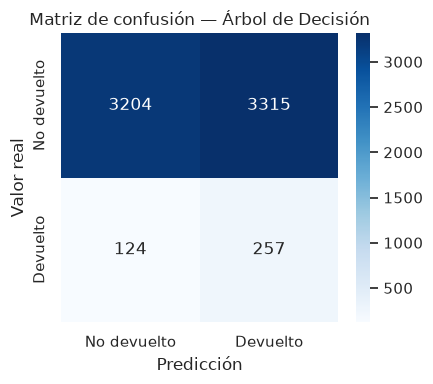

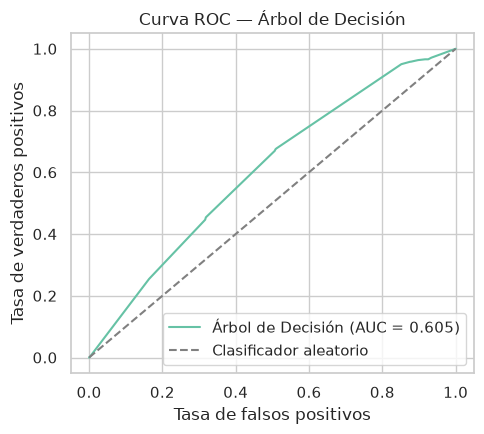

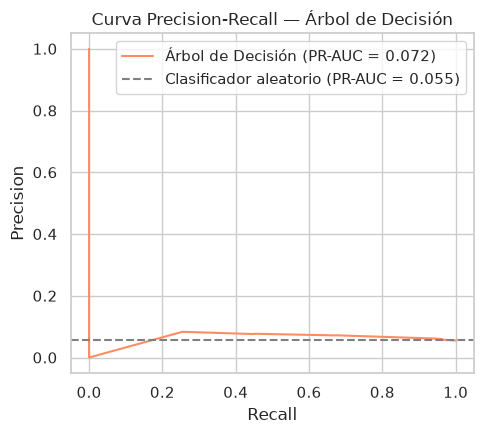

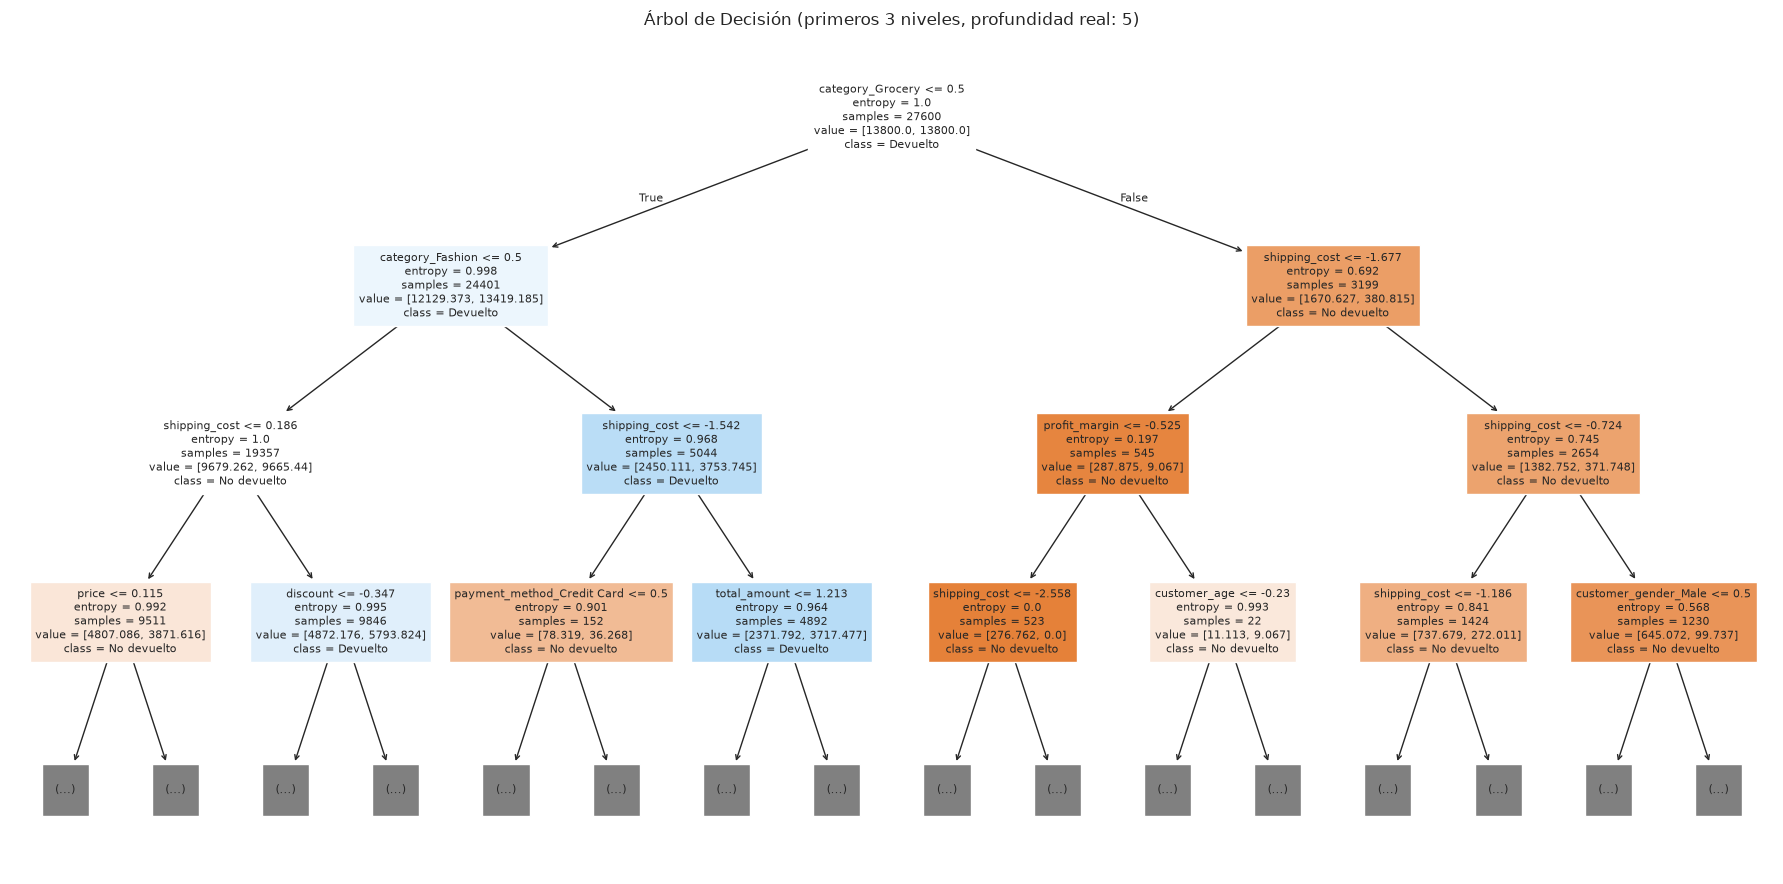

Modelo guardado.


In [9]:
#PREDICCIONES Y EVALUACION DEL ARBOL DE DECISION
proba_dt = modelo_dt.predict_proba(X_test)[:, 1]
evaluar_modelo(y_test, proba_dt, "Árbol de Decisión", "dt")

#dibujamos los primeros 3 niveles del arbol
plt.figure(figsize=(18, 9))
plot_tree(
    modelo_dt,
    max_depth=3,
    feature_names=list(feature_names),
    class_names=["No devuelto", "Devuelto"],
    filled=True,
    fontsize=8
)
plt.title(f"Árbol de Decisión (primeros 3 niveles, profundidad real: {modelo_dt.get_depth()})")
plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_arbol_visualizacion.png", dpi=150)
plt.show()

joblib.dump(modelo_dt, MODEL_DIR + "/decision_tree.joblib")
print("Modelo guardado.")

## Random Forest

In [10]:
#BUSQUEDA DE HIPERPARAMETROS Y ENTRENAMIENTO DEL RANDOM FOREST
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10],                 #Grid de hiperparametros sobre la que se buscara (3 x 5 x 3 x 3 x 2 x 2 = 540 combinaciones) *Ver que despues lo limitamos a 12 al hacer el RandomizedSearchCV
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2"],
    "class_weight": ["balanced", "balanced_subsample"]
}

#Modelo de Random Forest
rf = RandomForestClassifier(
    random_state=RANDOM_STATE
)

#Busqueda de los mejores hiperparametros, limitando a 12 combinaciones aleatorias de entre las 540 posibles
search_rf = RandomizedSearchCV(
    rf,
    param_dist,
    n_iter=12,                      
    scoring="average_precision",    
    cv=cv,
    random_state=RANDOM_STATE
)


#Entrenamiento del Random Forest
inicio = time.time()
search_rf.fit(X_train, y_train)
tiempos_entrenamiento["Random Forest"] = time.time() - inicio

modelo_rf = search_rf.best_estimator_

In [11]:
print(f'Mejores hiperparámetros: {search_rf.best_params_}')
print(f'Mejor PR-AUC en validación cruzada: {search_rf.best_score_:.4f}')
print(f'Tiempo total de ajuste: {tiempos_entrenamiento["Random Forest"]:.1f} s')

Mejores hiperparámetros: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': 'balanced'}
Mejor PR-AUC en validación cruzada: 0.0733
Tiempo total de ajuste: 310.1 s



 Random Forest
              precision    recall  f1-score   support

 No devuelto       0.95      0.76      0.85      6519
    Devuelto       0.08      0.36      0.13       381

    accuracy                           0.74      6900
   macro avg       0.52      0.56      0.49      6900
weighted avg       0.90      0.74      0.81      6900

Accuracy: 0.7396
Precision: 0.0806
Recall: 0.357
F1: 0.1315
F2: 0.2117
ROC-AUC: 0.6064
PR-AUC: 0.0724


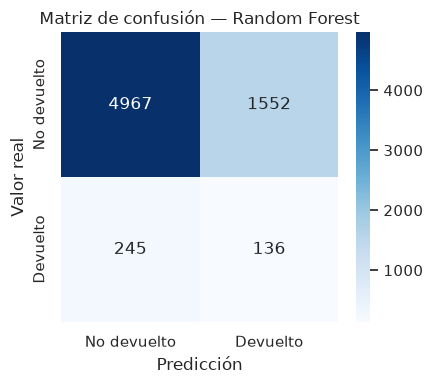

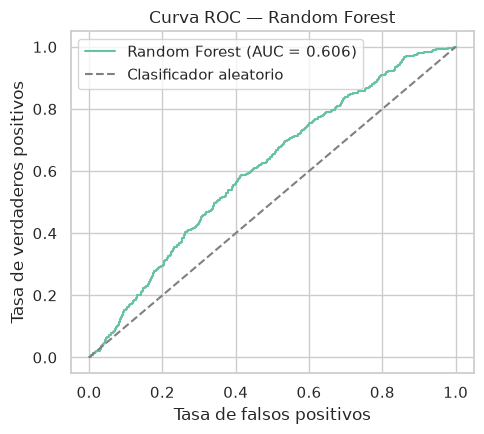

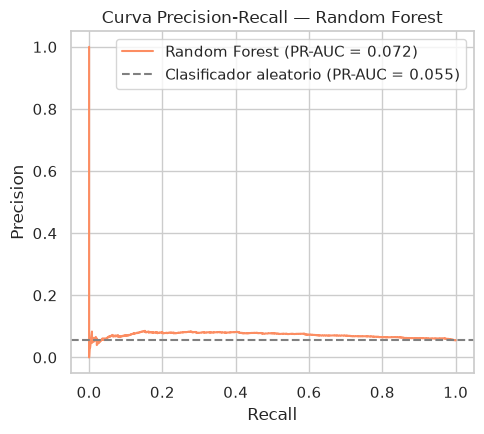

profit_margin                0.151336
shipping_cost                0.133456
price                        0.129051
total_amount                 0.127524
customer_age                 0.093468
category_Grocery             0.071140
category_Fashion             0.044461
discount                     0.038924
delivery_time_days           0.038634
quantity                     0.022554
customer_gender_Male         0.014366
payment_method_Debit Card    0.013829
dtype: float64


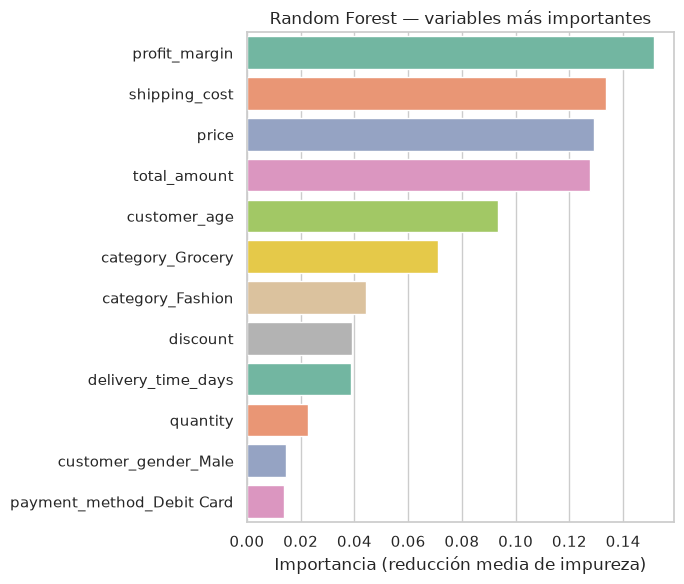

Modelo guardado.


In [12]:
#PREDICCIONES Y EVALUACION DEL RANDOM FOREST
proba_rf = modelo_rf.predict_proba(X_test)[:, 1]
evaluar_modelo(y_test, proba_rf, "Random Forest", "rf")


#Sacamos importancia de cada variable
importancias_rf = pd.Series(
    modelo_rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importancias_rf.head(12))

plt.figure(figsize=(7, 6))
sns.barplot(
    x=importancias_rf.head(12).values,
    y=importancias_rf.head(12).index,
    hue=importancias_rf.head(12).index,
    palette=PALETTE,
    legend=False
)
plt.xlabel("Importancia (reducción media de impureza)")
plt.ylabel("")
plt.title("Random Forest — variables más importantes")
plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_importancia_rf.png", dpi=150)
plt.show()

joblib.dump(modelo_rf, MODEL_DIR + "/random_forest.joblib")
print("Modelo guardado.")

## XGBoost

In [13]:
#BUSQUEDA DE HIPERPARAMETROS Y ENTRENAMIENTO DEL XGBoost


param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.6, 0.8, 1.0],              #Grid de hiperparametros sobre la que se buscara (4 x 5 x 4 x 3 x 3 x 3 x 3 = 6480 combinaciones) *Ver que despues lo limitamos a 25 al hacer el RandomizedSearchCV
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.5]
}


#XGBoost model, usando la libreria XGBoost y scale_pos_weight para tener en cuenta la variable minoritaria
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=RANDOM_STATE,
)

#Busqueda de los mejores hiperparametros, limitando a 25 combinaciones aleatorias de entre las 6480 posibles
search_xgb = RandomizedSearchCV(
    xgb_model,
    param_dist,
    n_iter=25,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE
)


#Entrenamiento del XGBoost
inicio = time.time()
search_xgb.fit(X_train, y_train)
tiempos_entrenamiento["XGBoost"] = time.time() - inicio

modelo_xgb = search_xgb.best_estimator_

print("Mejores parámetros:", search_xgb.best_params_)
print("PR-AUC CV:", round(search_xgb.best_score_, 4))
print("Tiempo:", round(tiempos_entrenamiento["XGBoost"], 1), "s")

Mejores parámetros: {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.6}
PR-AUC CV: 0.0746
Tiempo: 86.1 s



 XGBoost
              precision    recall  f1-score   support

 No devuelto       0.96      0.60      0.74      6519
    Devuelto       0.08      0.57      0.13       381

    accuracy                           0.60      6900
   macro avg       0.52      0.58      0.44      6900
weighted avg       0.91      0.60      0.70      6900

Accuracy: 0.5954
Precision: 0.076
Recall: 0.5669
F1: 0.134
F2: 0.2473
ROC-AUC: 0.615
PR-AUC: 0.0789


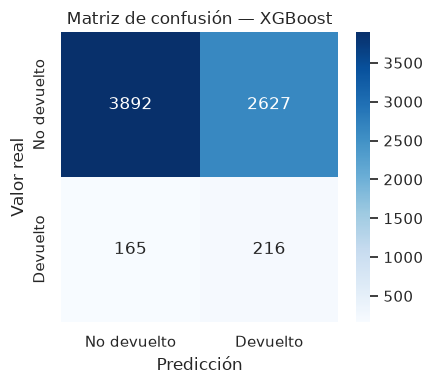

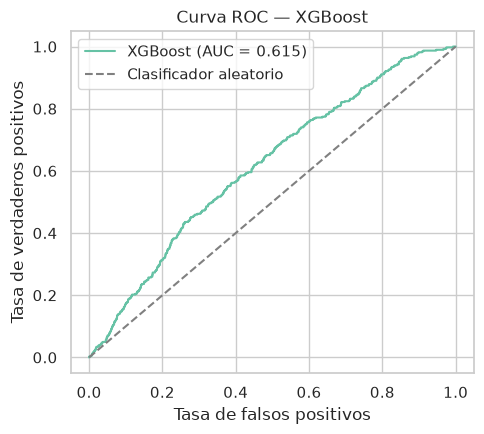

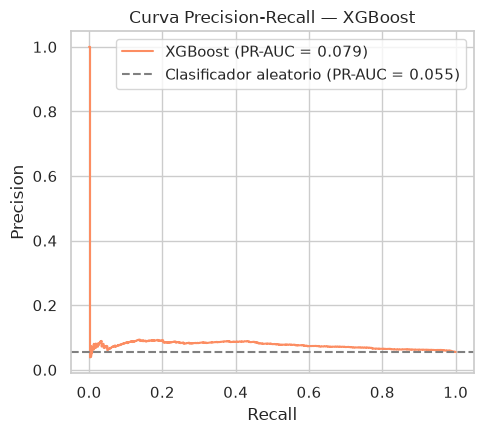

category_Grocery        0.292911
category_Fashion        0.101389
category_Electronics    0.050850
category_Sports         0.037989
category_Home           0.033551
profit_margin           0.032369
category_Toys           0.030832
shipping_cost           0.029116
price                   0.027784
total_amount            0.027214
discount                0.027004
customer_age            0.025903
dtype: float32


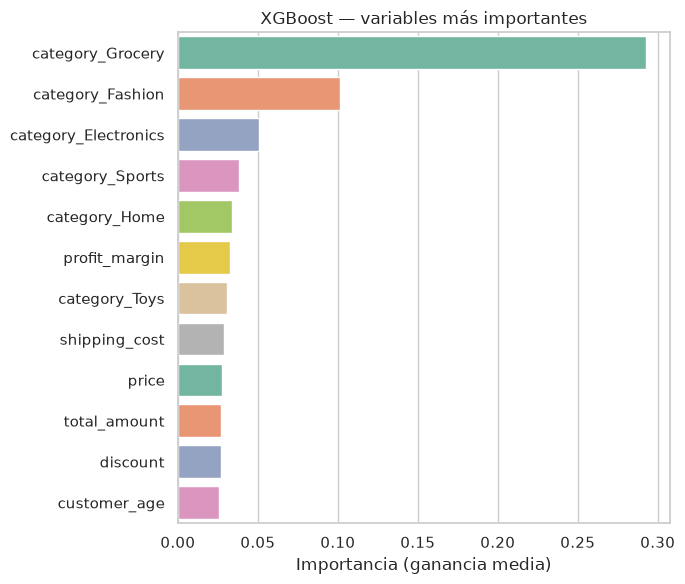

Modelo guardado.


In [14]:
#PREDICCIONES Y EVALUACION DEL XGBoost
proba_xgb = modelo_xgb.predict_proba(X_test)[:, 1]
evaluar_modelo(y_test, proba_xgb, "XGBoost", "xgb")

#sacamos importancia de cada variable
importancias_xgb = pd.Series(
    modelo_xgb.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importancias_xgb.head(12))

plt.figure(figsize=(7, 6))
sns.barplot(
    x=importancias_xgb.head(12).values,
    y=importancias_xgb.head(12).index,
    hue=importancias_xgb.head(12).index,
    palette=PALETTE,
    legend=False
)
plt.xlabel("Importancia (ganancia media)")
plt.ylabel("")
plt.title("XGBoost — variables más importantes")
plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_importancia_xgb.png", dpi=150)
plt.show()

joblib.dump(modelo_xgb, MODEL_DIR + "/xgboost_model.joblib")
print("Modelo guardado.")

## Red Neuronal (MLP)

In [15]:
def crear_modelo(meta, n_hidden=1, n_neurons=32, dropout=0.2, learning_rate=0.001):
    modelo = keras.Sequential()
    modelo.add(keras.layers.Input(shape=(meta["n_features_in_"],)))

    for i in range(n_hidden): 
        modelo.add(keras.layers.Dense(n_neurons, activation="relu")) #capa oculta con n_neurons neuronas con activacion relu
        modelo.add(keras.layers.Dropout(dropout))   #Añadimos Dropout, que apaga de forma aleatoria alguna neurona para el aprendizaje

    modelo.add(keras.layers.Dense(1, activation="sigmoid"))  #Añadimos unica neurona de salida con salida sigmoid al ser problema de clasificacion binaria

    #compilamos el modelo con funcion de perdida binary_crossentropy al ser clasificacion binaria, Adam optimizer y metrica AUC
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["AUC"]
    )
    return modelo

#Añadimos early stopping sobre la perdida de entrenamiento para parar si deja de mejorar
paradas = keras.callbacks.EarlyStopping(
    monitor="loss",
    patience=4,
    restore_best_weights=True
)

mlp = KerasClassifier(
    model=crear_modelo,
    n_hidden=1,
    n_neurons=32,
    dropout=0.2,
    learning_rate=0.001,
    epochs=25,
    batch_size=128,
    verbose=0,
    class_weight=class_weight_dict,
    callbacks=[paradas],
    random_state=RANDOM_STATE
)



param_dist = {
    "model__n_hidden": [1, 2, 3],
    "model__n_neurons": [16, 32, 64],                    #Grid de hiperparametros sobre la que se buscara (3 x 3 x 3 x 3 = 81 combinaciones) *Ver que despues lo limitamos a 8 al hacer el RandomizedSearchCV
    "model__dropout": [0.0, 0.2, 0.3],
    "model__learning_rate": [0.01, 0.001, 0.0005]
}


#Hacemos K-fold estratificado con 3 bolsas para reducir el tiempo de entrenamiento
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


#Busqueda de los mejores hiperparametros, limitando a 8 combinaciones aleatorias de entre las 81 posibles dado el alto tiempo de entrenamiento
search_mlp = RandomizedSearchCV(
    mlp,
    param_dist,
    n_iter=8,
    scoring="average_precision",
    cv=cv3,
    n_jobs=1,
    random_state=RANDOM_STATE
)

#Entrenamiento del MLP
inicio = time.time()
search_mlp.fit(X_train.values.astype("float32"), y_train.values)
tiempos_entrenamiento["MLP (Keras)"] = time.time() - inicio

modelo_mlp = search_mlp.best_estimator_

In [16]:
print("Mejores parámetros:", search_mlp.best_params_)
print("PR-AUC CV:", round(search_mlp.best_score_, 4))
print("Tiempo:", round(tiempos_entrenamiento["MLP (Keras)"], 1), "s")

Mejores parámetros: {'model__n_neurons': 32, 'model__n_hidden': 1, 'model__learning_rate': 0.001, 'model__dropout': 0.0}
PR-AUC CV: 0.0729
Tiempo: 204.1 s



 MLP (Keras)
              precision    recall  f1-score   support

 No devuelto       0.96      0.58      0.72      6519
    Devuelto       0.07      0.57      0.13       381

    accuracy                           0.58      6900
   macro avg       0.52      0.58      0.43      6900
weighted avg       0.91      0.58      0.69      6900

Accuracy: 0.5803
Precision: 0.0739
Recall: 0.5722
F1: 0.1309
F2: 0.2436
ROC-AUC: 0.6043
PR-AUC: 0.0726


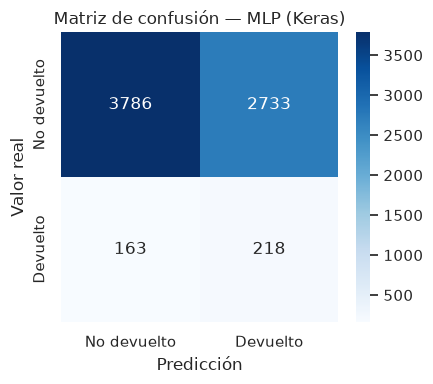

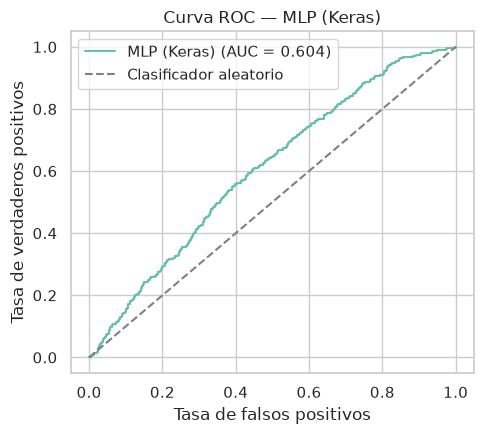

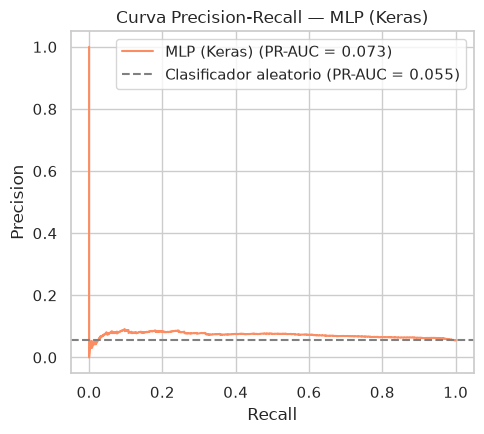

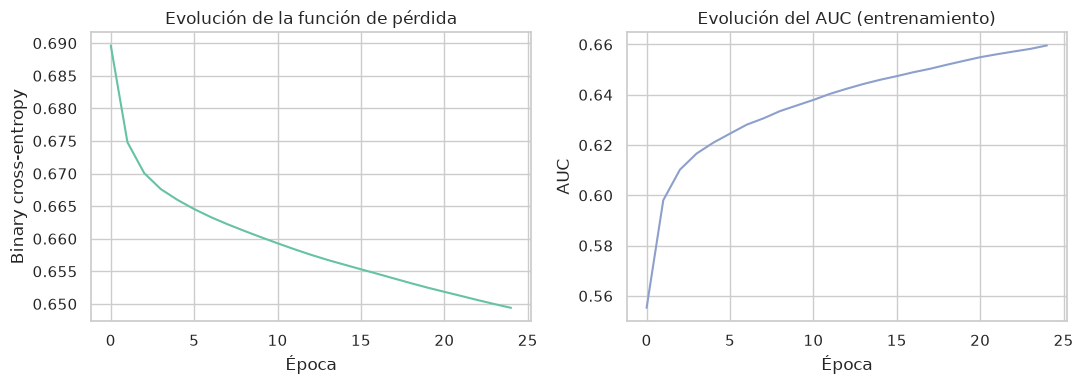

Épocas entrenadas: 25
Modelo guardado.


In [17]:
#PREDICCIONES Y EVALUACION DEL MLP
proba_mlp = modelo_mlp.predict_proba(X_test.values.astype("float32"))[:, 1]
evaluar_modelo(y_test, proba_mlp, "MLP (Keras)", "mlp")

history = modelo_mlp.history_

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

#Representamos funcion de perdida en funcion de la epoca
axes[0].plot(history["loss"], color=SET2[0])
axes[0].set_title("Evolución de la función de pérdida")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Binary cross-entropy")

#Representamos evolucion del AUC en funcion de las epocas
axes[1].plot(history["a_u_c"], color=SET2[2]) #scikeras guarda la metrica AUC en el historial con el nombre a_u_c
axes[1].set_title("Evolución del AUC (entrenamiento)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("AUC")

plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_mlp_historial.png", dpi=150)
plt.show()

print("Épocas entrenadas:", len(history["loss"]))

modelo_mlp.model_.save(MODEL_DIR + "/mlp_keras.keras")
print("Modelo guardado.")

## Comparación final

In [18]:
tabla_comparativa = pd.DataFrame(resultados_modelos).T #sacamos los resultados de metricas de los modelos

tabla_comparativa["Tiempo de ajuste (s)"] = pd.Series(tiempos_entrenamiento)  #Le añadimos a la tabla los tiempos de ajuste

tabla_comparativa = tabla_comparativa[
    ["Accuracy", "Precision", "Recall", "F1", "F2", "ROC-AUC", "PR-AUC",
     "Tiempo de ajuste (s)"]                                                     #Resultados de los entrenamientos y evaluacion de los modelos
].astype(float)

tabla_comparativa = tabla_comparativa.sort_values(
    "PR-AUC",
    ascending=False                           #Ordenamos en funcion de nuestra metrica principal, el PR-AUC
).round(4)

print(tabla_comparativa)
tabla_comparativa.to_csv(
    RESULTS_DIR + "/tabla_comparativa_modelos.csv"
)

                     Accuracy  Precision  Recall      F1      F2  ROC-AUC  \
XGBoost                0.5954     0.0760  0.5669  0.1340  0.2473   0.6150   
Regresión Logística    0.5103     0.0737  0.6798  0.1329  0.2569   0.6179   
MLP (Keras)            0.5803     0.0739  0.5722  0.1309  0.2436   0.6043   
Random Forest          0.7396     0.0806  0.3570  0.1315  0.2117   0.6064   
Árbol de Decisión      0.5016     0.0719  0.6745  0.1300  0.2522   0.6051   

                     PR-AUC  Tiempo de ajuste (s)  
XGBoost              0.0789               86.1097  
Regresión Logística  0.0783                5.2689  
MLP (Keras)          0.0726              204.0922  
Random Forest        0.0724              310.0658  
Árbol de Decisión    0.0719              111.6608  


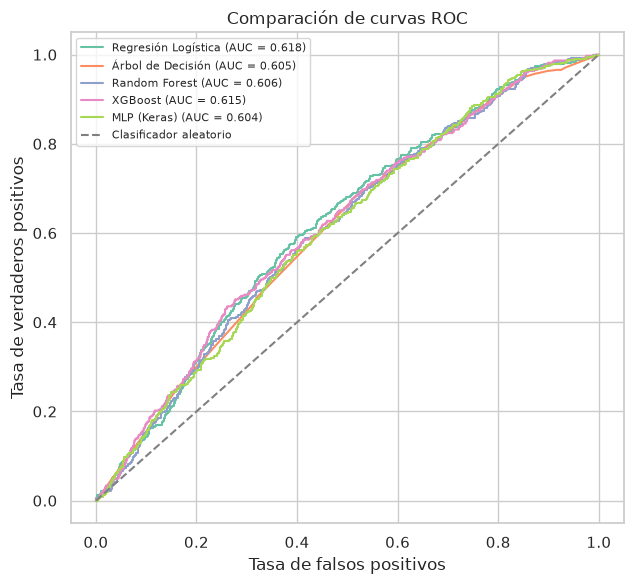

In [19]:
probas = {
    "Regresión Logística": proba_lr,
    "Árbol de Decisión": proba_dt,
    "Random Forest": proba_rf,
    "XGBoost": proba_xgb,           #diccionario con las predicciones de los modelos en funcion de probabilidades de que un pedido sea devuelto
    "MLP (Keras)": proba_mlp
}

plt.figure(figsize=(6.5, 6))

#Dibujamos curvas ROC de todos los modelos
for (nombre, proba), color in zip(probas.items(), SET2):
    fpr, tpr, _ = roc_curve(y_test, proba)                                  
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, color=color, label=nombre + " (AUC = " + str(round(auc, 3)) + ")")

plt.plot([0, 1], [0, 1], "--", color="gray", label="Clasificador aleatorio") #clasificador aleatorio
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Comparación de curvas ROC")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_roc_comparativo.png", dpi=150)
plt.show()

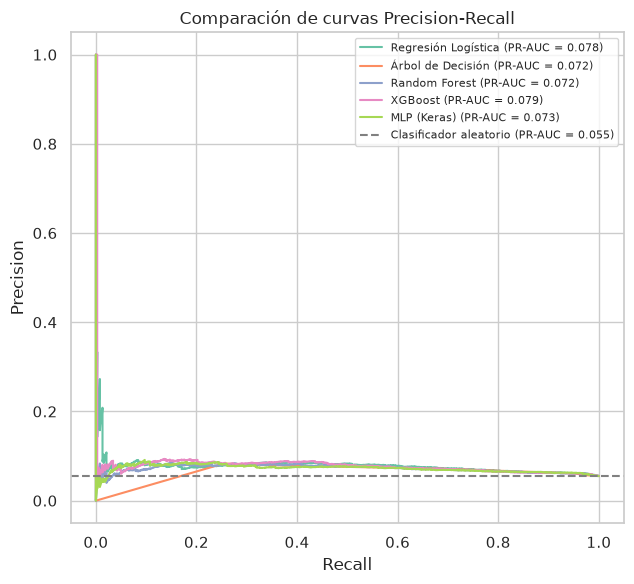

In [20]:
plt.figure(figsize=(6.5, 6))

#Dibujamos curvas Precision-Recall de todos los modelos
for (nombre, proba), color in zip(probas.items(), SET2):
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    plt.plot(recall, precision, color=color, label=nombre + " (PR-AUC = " + str(round(ap, 3)) + ")")

plt.axhline(y_test.mean(), linestyle="--", color="gray",
            label="Clasificador aleatorio (PR-AUC = " + str(round(y_test.mean(), 3)) + ")") #clasificador aleatorio
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Comparación de curvas Precision-Recall")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_pr_comparativo.png", dpi=150)
plt.show()

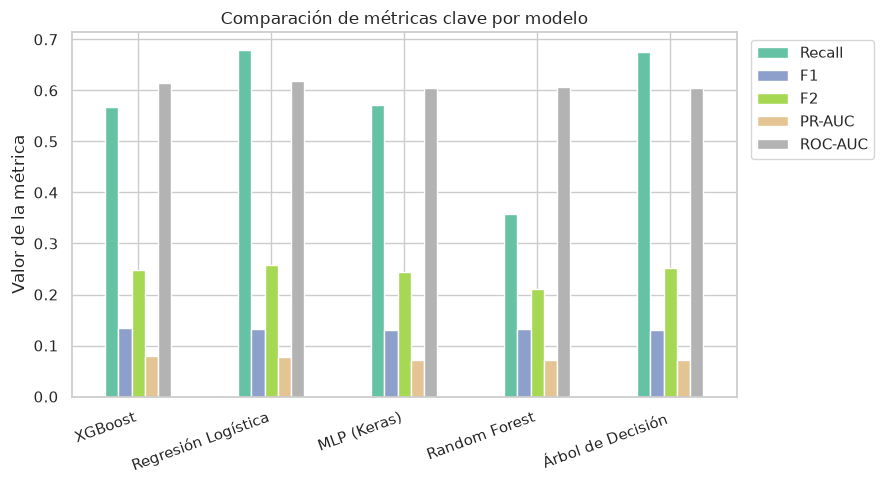

In [21]:
#Dibujamos metricas de todos los modelos
metricas = tabla_comparativa[
    ["Recall", "F1", "F2", "PR-AUC", "ROC-AUC"]
]

metricas.plot(kind="bar", figsize=(9, 5), colormap=PALETTE)
plt.ylabel("Valor de la métrica")
plt.title("Comparación de métricas clave por modelo")
plt.xticks(rotation=20, ha="right")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR + "/modelado_barras_comparativas.png", dpi=150)
plt.show()